# Assignment 06: A First-Principles Species Distribution Model

## BIO597 Spatial Analysis of Biodiversity

This assignment asks you to build and interpret a simple one-variable species distribution model without using an SDM package. You will choose one amphibian species, describe the environmental values at its occurrence records, compare those values with background environments, create a suitability curve, and project that curve across Maine.

## Deliverable

Submit a completed notebook with code, maps, plots, and short written interpretations. Your goal is to show that you understand the moving parts of an SDM before we use more automated modeling tools.

## Learning goals

By the end of this assignment, you should be able to:

* describe the difference between occurrence, background, and absence data
* extract one raster predictor at species occurrence records
* compare used environments with available environments
* create a simple environmental suitability score
* project a suitability score across raster space
* explain why a conceptual SDM is not the same as a validated prediction model

## Data

Use:

* `Amphibians_ME/Amphibians_ME.csv` for occurrence records
* `/home/jovyan/shared-readwrite/bioclim/` for one environmental variable of your choice that is NOT mean annual temperature
* `../labs/ME_ShapeFiles/Maine_State_Boundary.shp` for the Maine boundary

You may use the same species as the lab or choose a different species with at least 100 usable records.

## 1. Import packages

Import `pandas`, `geopandas`, `rioxarray`, `xarray`, `numpy`, `matplotlib.pyplot`, and `Path`.

In [2]:
# Import packages here.
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rioxarray as rxr
import xarray as xr

## 2. Load and combine the Maine boundary

Read the Maine state boundary shapefile, inspect its CRS and shape, and dissolve it to one row.

In [3]:
boundary_path = "../labs/ME_ShapeFiles/Maine_State_Boundary.shp"
# Read the boundary.
maine_boundary = gpd.read_file("../labs/ME_ShapeFiles/Maine_State_Boundary.shp")
# Print its shape and CRS.
print(maine_boundary.shape)
print(maine_boundary.crs)
# Dissolve it to one row.
maine_boundary = maine_boundary.dissolve()

(6204, 10)
EPSG:4326


## 3. Open and clip environmental data

Select one environmental variable of your choosing that is NOT mean annual temperature. You can choose one you think will work well or one you think is less important for the study organism. Open the variable .tif file with `masked=True`, clip it to Maine, and remove the band dimension with `squeeze()`.


In [4]:
bioclim_path = Path("/home/jovyan/shared/bioclim")

# Open bio5 with rxr.open_rasterio().
bio5 = rxr.open_rasterio(
    bioclim_path / "wc2.1_2.5m_bio_5.tif",
    masked=True,
)

# Clip it to the dissolved Maine boundary.
# Squeeze out the band dimension.
bio5_maine = bio5.rio.clip(
    maine_boundary.geometry,
    maine_boundary.crs,
    drop=True,
    from_disk=True,
).squeeze()



# Convert to degrees Celsius if needed.

if float(bio5_maine.max()) > 100:
    bio5_maine_c = bio5_maine / 10
else:
    bio5_maine_c = bio5_maine


bio5_maine_c.name = "annual_mean_temperature_c"
bio5_maine_c


<xarray.DataArray 'annual_mean_temperature_c' (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  48.459999084473
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -30.760000228882
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 4. Map your environmental variable

Create a map of the clipped temperature raster. Include a title.

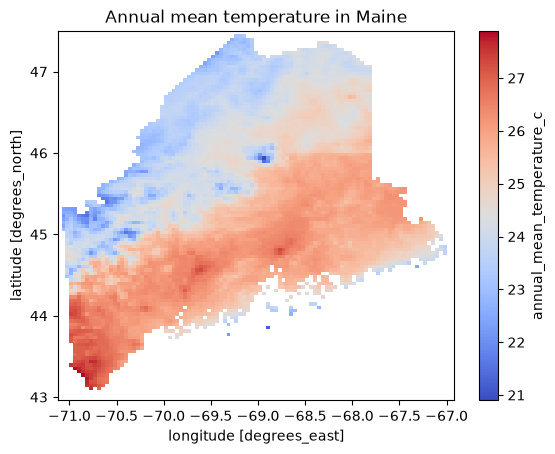

In [5]:
# Plot annual mean temperature for Maine.

bio5_maine_c.plot(cmap="coolwarm")
plt.title("Annual mean temperature in Maine")
plt.show()

## 5. Load and prepare amphibian occurrence records

Read the tab-delimited amphibian file. Keep `gbifID`, `species`, longitude, latitude, coordinate uncertainty, and year. Convert coordinates to numeric values and remove records missing species or coordinates.

In [6]:
amphibians = pd.read_csv(
    "Amphibians_ME/Amphibians_ME.csv",
    sep="\t",
    low_memory=False,
)

columns_to_keep = [
    "gbifID",
    "species",
    "decimalLongitude",
    "decimalLatitude",
    "coordinateUncertaintyInMeters",
    "year",
]

# Keep only columns_to_keep.
amphibians = amphibians[columns_to_keep].copy()


# Convert longitude and latitude to numeric values.
amphibians["decimalLongitude"] = pd.to_numeric(amphibians["decimalLongitude"], errors="coerce")
amphibians["decimalLatitude"] = pd.to_numeric(amphibians["decimalLatitude"], errors="coerce")
# Drop records missing species, longitude, or latitude.

amphibians = amphibians.dropna(subset=["species", "decimalLongitude", "decimalLatitude"]).copy()

## 6. Choose one species

Display the most common species, then choose one species with at least 100 records. Store its scientific name as `target_species`.

In [7]:
# Display species counts.
amphibians["species"].value_counts().head(12)

species
Aquarana clamitans           2966
Plethodon cinereus           2864
Pseudacris crucifer          2801
Anaxyrus americanus          2800
Boreorana sylvatica          2794
Ambystoma maculatum          2511
Lithobates catesbeianus      2302
Lithobates palustris         1626
Dryophytes versicolor        1411
Notophthalmus viridescens    1029
Lithobates pipiens            561
Eurycea bislineata            516
Name: count, dtype: int64

In [9]:
target_species = "Anaxyrus americanus"

# Filter the occurrence table to your target species.
presence = amphibians.loc[amphibians["species"] == target_species].copy()
# Display the number of records and the first five rows.
print(target_species)
print(presence.shape)
presence.head()

Anaxyrus americanus
(2800, 6)


,gbifID,species,decimalLongitude,decimalLatitude,coordinateUncertaintyInMeters,year
10,6520667379,Anaxyrus americanus,-69.794576,44.203264,300.0,2026.0
23,6520596403,Anaxyrus americanus,-70.456821,43.994143,9.0,2026.0
27,6520566821,Anaxyrus americanus,-70.684983,44.393545,5.0,2026.0
36,6520466321,Anaxyrus americanus,-68.459563,44.685825,876.0,2026.0
45,6520413611,Anaxyrus americanus,-69.822108,43.874055,10.0,2026.0


**Why did you choose this species?** Include one sentence about record count and one sentence about why it may or may not be appropriate for this simple model.
                                                                                                                                         
The American toad has 2800 observations or the 4th most of any of the species. This gives ys alot to work with. It may be good for this simple model because it has a strong warm temperature limitation

## 7. Create an occurrence GeoDataFrame

Use longitude and latitude to create point geometry. Assign `EPSG:4326`. Confirm that the occurrence CRS and raster CRS are compatible.

In [11]:
# Create presence_gdf.
presence_gdf = gpd.GeoDataFrame(
    presence,
    geometry=gpd.points_from_xy(
        presence["decimalLongitude"],
        presence["decimalLatitude"],
    ),
    crs="EPSG:4326",
)



# Print the occurrence CRS and raster CRS.

print("Occurrence CRS:", presence_gdf.crs)
print("Raster CRS:", bio5_maine_c.rio.crs)

Occurrence CRS: EPSG:4326
Raster CRS: EPSG:4326


**CRS check:** Explain why coordinate systems matter before extracting raster values at points.

You must check that the CRS aligns because if not the 2 data sources will not map on to each other correctly

## 8. Extract environment at occurrence points

Create `xarray.DataArray` objects for point longitude and latitude. Use `.sel(..., method="nearest")` to extract BIO1 values at occurrence records. Add the extracted values to a column named `bio1_c`.

In [14]:
# Create point_x and point_y.
point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

# Extract temperature values.
presence_temp = bio5_maine_c.sel(
    x=point_x,
    y=point_y,
    method="nearest",
)
# Add them to presence_gdf as bio1_c.
presence_gdf["bio5_c"] = presence_temp.values

# Drop records with missing bio1_c.
presence_gdf = presence_gdf.dropna(subset=["bio5_c"]).copy()

# Rebuild point_x and point_y after dropping missing values.
point_x = xr.DataArray(presence_gdf.geometry.x.values, dims="record")
point_y = xr.DataArray(presence_gdf.geometry.y.values, dims="record")

presence_gdf[["species", "decimalLongitude", "decimalLatitude", "bio5_c"]].head()

,species,decimalLongitude,decimalLatitude,bio5_c
10,Anaxyrus americanus,-69.794576,44.203264,26.248001
23,Anaxyrus americanus,-70.456821,43.994143,26.136000
27,Anaxyrus americanus,-70.684983,44.393545,25.955999
36,Anaxyrus americanus,-68.459563,44.685825,26.076000
45,Anaxyrus americanus,-69.822108,43.874055,25.222223


## 9. Summarize occurrence environment

Calculate the count, mean, standard deviation, minimum, and maximum of `bio1_c` at occurrence records.

In [15]:
# Summarize occurrence temperature values.
presence_mean = presence_gdf["bio5_c"].mean()
presence_sd = presence_gdf["bio5_c"].std()

print(f"Number of usable records: {len(presence_gdf)}")
print(f"Mean occurrence temperature: {presence_mean:.2f} C")
print(f"SD of occurrence temperature: {presence_sd:.2f} C")
print(f"Minimum occurrence temperature: {presence_gdf['bio5_c'].min():.2f} C")
print(f"Maximum occurrence temperature: {presence_gdf['bio5_c'].max():.2f} C")

Number of usable records: 2627
Mean occurrence temperature: 25.41 C
SD of occurrence temperature: 1.22 C
Minimum occurrence temperature: 20.90 C
Maximum occurrence temperature: 27.89 C


**Interpretation:** In two or three sentences, describe the environmental range represented by your species records.
The Maximim temperature this species occurred in was 27.89 degrees C. It has a mean maximim temperature of 25.41 degrees C.

## 10. Sample background environment

Create a random sample of up to 5,000 valid cells from Maine for your environmental variable. Use a random seed so your results are reproducible.

In [16]:
rng = np.random.default_rng(597)

# Create an array of valid raster environmental values.
valid_temperature = bio5_maine_c.values
valid_temperature = valid_temperature[np.isfinite(valid_temperature)]
# Randomly sample up to 5000 cells without replacement.
background_temp = rng.choice(
    valid_temperature,
    size=min(5000, valid_temperature.size),
    replace=False,
)
# Print the background sample size, mean, and standard deviation.
print(f"Background sample size: {len(background_temp)}")
print(f"Mean background temperature: {background_temp.mean():.2f} C")
print(f"SD background temperature: {background_temp.std():.2f} C")

Background sample size: 5000
Mean background temperature: 25.00 C
SD background temperature: 1.13 C


## 11. Compare occurrence and background environments

Make overlapping histograms of occurrence environment and background environment. Use density-scaled histograms so the shapes can be compared even though the sample sizes differ.

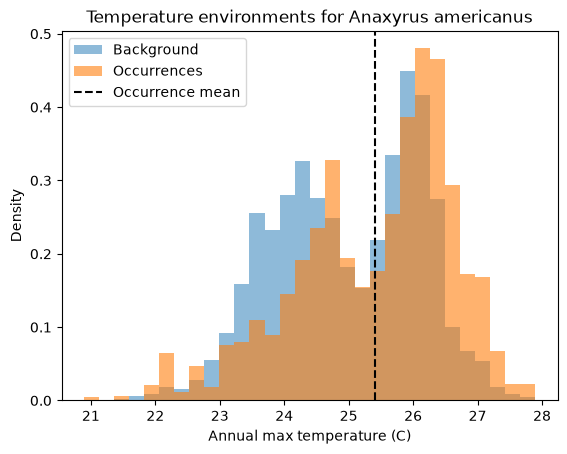

In [19]:
# Create an overlapping histogram of background and occurrence temperatures.
plt.hist(background_temp, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_gdf["bio5_c"], bins=30, alpha=0.6, density=True, label="Occurrences")
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Annual max temperature (C)")
plt.ylabel("Density")
plt.title(f"Temperature environments for {target_species}")
plt.legend()
plt.show()


**Interpretation:** Does your species appear to use a narrow or broad subset of available environmental space? Explain using your plot.

The Amarican toad seems to use a slightly broader subset of available environmental space as it has some more low and high end observations but there does apear to be a large overlap between the 2 spaces.

## 12. Define a suitability function

Write a function that takes `observed`, `optimum`, and `tolerance` and returns:

```python
np.exp(-0.5 * ((observed - optimum) / tolerance) ** 2)
```

This creates a score near 1 when observed environment is close to the optimum and closer to 0 as temperature gets farther away.

In [25]:
def environmental_suitability(observed, optimum, tolerance):
    z = (observed - optimum) / tolerance
    return np.exp(-0.5 * z**2)


x_temp = np.linspace(
    float(np.nanmin(bio5_maine_c.values)),
    float(np.nanmax(bio5_maine_c.values)),
    200,
)





## 13. Plot your suitability curve

Use the mean occurrence environmental value as the optimum and the standard deviation of occurrence as the tolerance. Plot suitability across the full range of Maine BIO1 values.

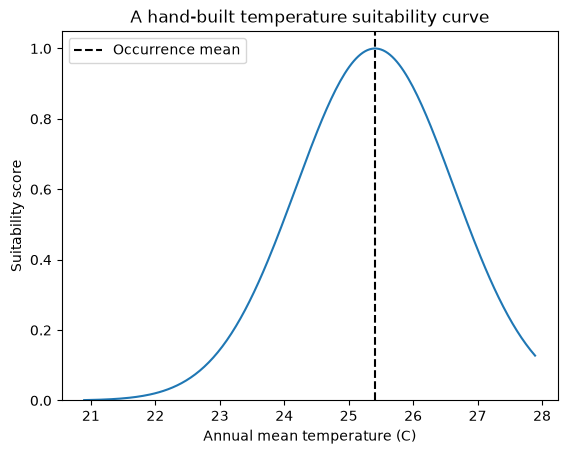

In [29]:
# Calculate presence_mean and presence_sd.
suitability_curve = environmental_suitability(
    x_temp,
    optimum=presence_mean,
    tolerance=presence_sd,
)

# Create a sequence of environmental values across the raster range.


# Calculate suitability for those values.

suitability = xr.apply_ufunc(
    environmental_suitability,
    bio5_maine_c,
    presence_mean,
    presence_sd,
)
# Plot the curve.

plt.plot(x_temp, suitability_curve)
plt.axvline(presence_mean, color="black", linestyle="--", label="Occurrence mean")
plt.xlabel("Annual mean temperature (C)")
plt.ylabel("Suitability score")
plt.ylim(0, 1.05)
plt.title("A hand-built temperature suitability curve")
plt.legend()
plt.show()

**Interpretation:** What value receives the highest suitability score? What does the tolerance control?

the highest suitability is around 25.3 degrees. tolerance controls the standered deviation of the curve or the variablity. 


## 14. Project suitability across Maine

Apply your suitability function to every cell in the environmental raster. Keep missing raster cells missing.

In [30]:
# Use xr.apply_ufunc() to apply environmental_suitability to the raster.

suitability = xr.apply_ufunc(
    environmental_suitability,
    bio5_maine_c,
    presence_mean,
    presence_sd,
)


# Store the result as suitability.
suitability = suitability.where(np.isfinite(bio5_maine_c))
suitability = suitability.rio.write_crs(bio5_maine_c.rio.crs)
suitability.name = "environmental_suitability"
suitability
# Mask cells where the environmental raster is missing.


<xarray.DataArray 'environmental_suitability' (y: 109, x: 101)> Size: 88kB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(109, 101))
Coordinates:
  * y            (y) float64 872B 47.48 47.44 47.4 47.35 ... 43.06 43.02 42.98
  * x            (x) float64 808B -71.1 -71.06 -71.02 ... -67.02 -66.98 -66.94
    band         int64 8B 1
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:       Area
    STATISTICS_MAXIMUM:  48.459999084473
    STATISTICS_MEAN:     nan
    STATISTICS_MINIMUM:  -30.760000228882
    STATISTICS_STDDEV:   nan
    scale_factor:        1.0
    add_offset:          0.0

## 15. Map suitability

Create a continuous suitability map with values from 0 to 1.

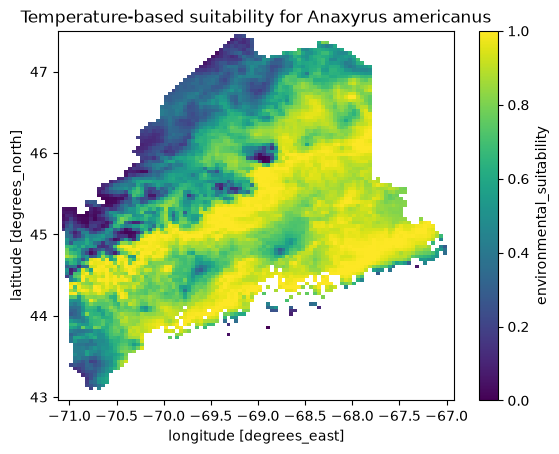

In [31]:
# Plot the suitability raster.
suitability.plot(vmin=0, vmax=1, cmap="viridis")
plt.title(f"Temperature-based suitability for {target_species}")
plt.show()

## 16. Overlay occurrence points

Plot your suitability raster and overlay the occurrence points. This is a visual check, not a formal validation.

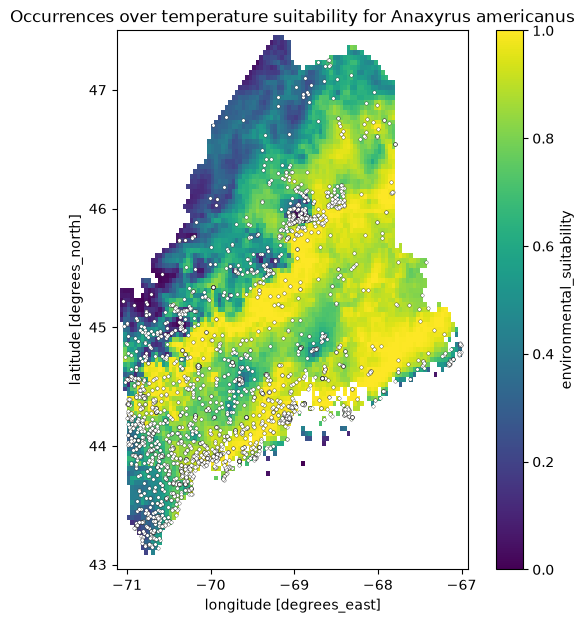

In [32]:
# Plot suitability and overlay presence_gdf points.
fig, ax = plt.subplots(figsize=(7, 7))
suitability.plot(ax=ax, vmin=0, vmax=1, cmap="viridis")
presence_gdf.plot(ax=ax, markersize=6, color="white", edgecolor="black", linewidth=0.2)
ax.set_title(f"Occurrences over temperature suitability for {target_species}")
plt.show()

**Visual check:** Do occurrence points generally fall in areas with higher predicted suitability? Describe any mismatch you see.

There does not apear to be strong correlation between occurrences and highest suitable max temp. This may be a result of the fact that max temp does not control their range in this region.

## 17. Compare occurrence and background suitability scores

Extract suitability at occurrence records. Also calculate suitability for your background environmental values. Compare the two distributions with histograms.

Mean occurrence suitability: 0.702
Mean background suitability: 0.698


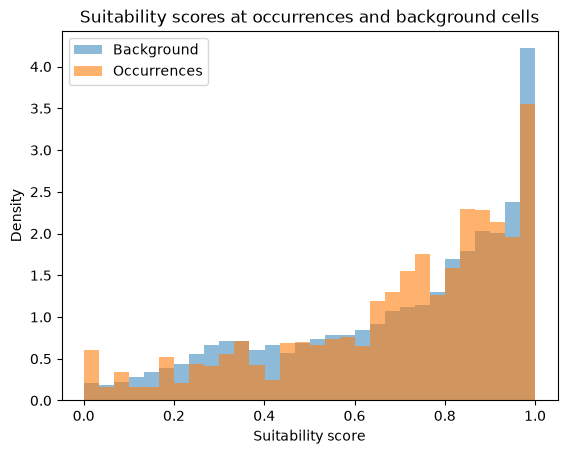

In [34]:
# Extract suitability at occurrence points.
presence_suitability = suitability.sel(
    x=point_x,
    y=point_y,
    method="nearest",
).values


# Calculate suitability for background environmental values.
background_suitability = environmental_suitability(
    background_temp,
    optimum=presence_mean,
    tolerance=presence_sd,
)
# Print mean occurrence suitability and mean background suitability.
print(f"Mean occurrence suitability: {np.nanmean(presence_suitability):.3f}")
print(f"Mean background suitability: {np.nanmean(background_suitability):.3f}")
# Plot overlapping histograms.

plt.hist(background_suitability, bins=30, alpha=0.5, density=True, label="Background")
plt.hist(presence_suitability, bins=30, alpha=0.6, density=True, label="Occurrences")
plt.xlabel("Suitability score")
plt.ylabel("Density")
plt.title("Suitability scores at occurrences and background cells")
plt.legend()
plt.show()

**Interpretation:** Did your model score occurrence records higher than background locations? What would it mean if it did not?

The model scored occurence slightly high then background. If it did not it would mean the model is performing worse then a random sample.

## 18. Change the tolerance

Create two additional suitability rasters: one with half the observed standard deviation and one with twice the observed standard deviation. Map all three side by side.

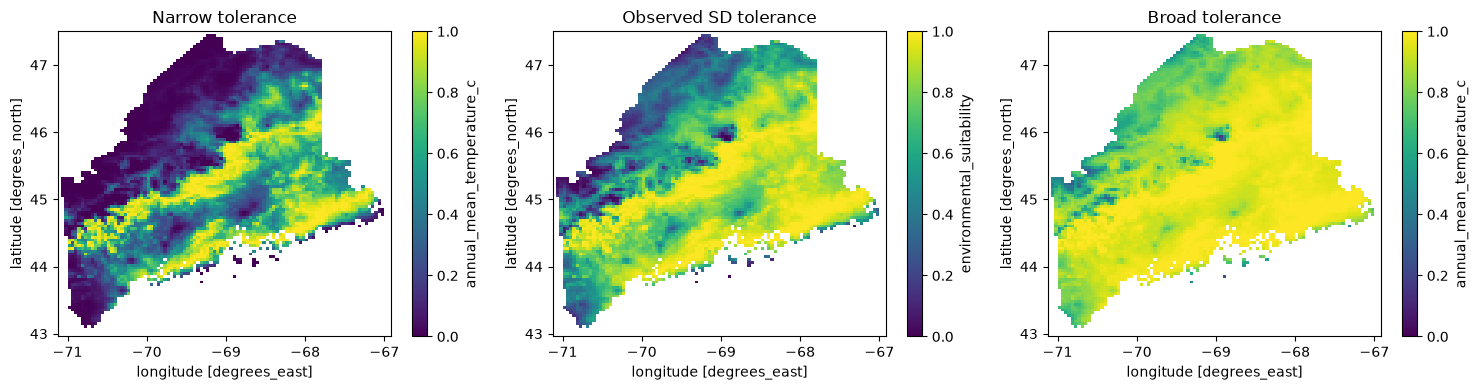

In [36]:
# Create narrow_suitability using presence_sd / 2.

narrow_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio5_maine_c,
    presence_mean,
    presence_sd / 2,
).where(np.isfinite(bio5_maine_c))

# Create broad_suitability using presence_sd * 2.
broad_suitability = xr.apply_ufunc(
    environmental_suitability,
    bio5_maine_c,
    presence_mean,
    presence_sd * 2,
).where(np.isfinite(bio5_maine_c))

# Plot narrow, original, and broad suitability maps side by side.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
narrow_suitability.plot(ax=axes[0], vmin=0, vmax=1, cmap="viridis")
axes[0].set_title("Narrow tolerance")
suitability.plot(ax=axes[1], vmin=0, vmax=1, cmap="viridis")
axes[1].set_title("Observed SD tolerance")
broad_suitability.plot(ax=axes[2], vmin=0, vmax=1, cmap="viridis")
axes[2].set_title("Broad tolerance")
plt.tight_layout()
plt.show()


**Interpretation:** How does tolerance affect the predicted distribution? Which tolerance seems most defensible for your species, and why?

Tolerance makes less regions suitable suitable and gives out lower suitablitly scores. I believe the braod tolerance is most defensble because the toad is distributed throughout the state and it doesnt seem like max temp is the factor controling it. 

## 19. Threshold the continuous map

Convert your continuous suitability map to a binary suitable/unsuitable map using a threshold of your choice. Report the fraction of Maine climate cells labeled suitable.

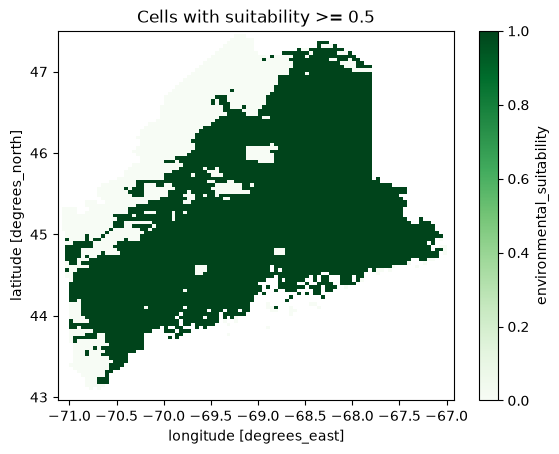

Fraction of Maine climate cells labeled suitable: 75.90%


In [40]:
threshold = 0.5
suitable_binary = suitability >= threshold
suitable_binary = suitable_binary.where(np.isfinite(bio5_maine_c))

# Create a binary suitability map.
suitable_binary.plot(cmap="Greens")
plt.title(f"Cells with suitability >= {threshold}")
plt.show()

# Plot it.
# Calculate the fraction of non-missing cells labeled suitable.
suitable_fraction = float(suitable_binary.mean(skipna=True))
print(f"Fraction of Maine climate cells labeled suitable: {suitable_fraction:.2%}")

**Threshold justification:** Why did you choose this threshold? How would the map change with a lower or higher threshold?

I decided to stick with .5 because i feel it representede what the acctual observations showed the best. a higher threshold would shrink the map and a lower threshold would grow the map. 

## 20. Save your outputs

Save your continuous suitability raster as `Assignment06_suitability.tif`. Save a CSV containing your occurrence records and extracted BIO1 values as `Assignment06_presence.csv`.

In [41]:
# Save the suitability raster.

suitability.rio.to_raster("Assignment06_suitability.tif")
# Save the occurrence table with extracted temperature values.
presence_table = presence_gdf.drop(columns="geometry")
presence_table["envrionmental_suitability"] = presence_suitability
presence_table.to_csv("Assignment06_presence_envrionmental_suitability.csv", index=False)

## Final reflection

Answer each question in two or three sentences.

1. In this exercise, what information came from occurrence records and what information came from the environmental raster?

The occerence records gave the cordinates of the observartions and the environmental raster gave the temperatures at those cordinates.
2. Why did we compare occurrence environment with background environment?
This looks at if the occurrence environment differs from what could be expected at random
3. Why is this suitability score not the same as probability of presence?
probability of presence predicts if a animal will be there while a suitablity score just says how good the environment is for that organism
4. Name two ecological or sampling processes ignored by this one-variable model.
the habitat of the area is ignored like forest, plain, field etc. also amphibians need water so rainfall is ignored. 
5. What would a full SDM package add beyond this first-principles workflow?


## Submit your work

Run the notebook from top to bottom. Make sure all maps, plots, saved files, and written answers are complete. Then commit and push the completed notebook to your class GitHub repository.

```bash
git add docs/assignments/Assignment-06-FirstPrinciplesSDM.ipynb
git commit -m "Complete first principles SDM assignment"
git push
```